In [ ]:
#import
import numpy as np
import pandas as pd
import matplotlib as mpt
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("white")

import requests
from bs4 import BeautifulSoup

from google.colab import drive
drive.mount('/content/drive')

df = pd.read_csv('/content/drive/MyDrive/top-500-movies.csv')
pd.options.display.float_format = '{:.0f}'.format
df

Mounted at /content/drive


,rank,release_date,title,url,production_cost,domestic_gross,worldwide_gross,opening_weekend,mpaa,genre,theaters,runtime,year
0,1,2019-04-23,Avengers: Endgame,/movie/Avengers-Endgame-(2019)#tab=summary,400000000,858373000,2797800564,357115007,PG-13,Action,4662,181,2019
1,2,2011-05-20,Pirates of the Caribbean: On Stranger Tides,/movie/Pirates-of-the-Caribbean-On-Stranger-Ti...,379000000,241071802,1045713802,90151958,PG-13,Adventure,4164,136,2011
2,3,2015-04-22,Avengers: Age of Ultron,/movie/Avengers-Age-of-Ultron#tab=summary,365000000,459005868,1395316979,191271109,PG-13,Action,4276,141,2015
3,4,2015-12-16,Star Wars Ep. VII: The Force Awakens,/movie/Star-Wars-Ep-VII-The-Force-Awakens#tab=...,306000000,936662225,2064615817,247966675,PG-13,Adventure,4134,136,2015
4,5,2018-04-25,Avengers: Infinity War,/movie/Avengers-Infinity-War#tab=summary,300000000,678815482,2048359754,257698183,PG-13,Action,4474,156,2018
...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,496,2013-02-06,A Good Day to Die Hard,/movie/Die-Hard-5#tab=summary,92000000,67349198,304249198,24834845,R,Action,3555,98,2013
496,497,2004-04-09,The Alamo,/movie/Alamo-The-(2004)#tab=summary,92000000,22406362,23911362,9124701,PG-13,Western,2609,137,2004
497,498,1995-12-22,Cutthroat Island,/movie/Cutthroat-Island#tab=summary,92000000,10017322,18517322,2371415,PG-13,Adventure,1619,NaN,1995
498,499,2013-12-19,The Secret Life of Walter Mitty,/movie/Secret-Life-of-Walter-Mitty-The-(2012)#...,91000000,58236838,187861183,12765508,PG,Adventure,2922,114,2013


# **แสดงคุณลักษณะเบื้องต้น แสดงค่าสถิติ**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   rank             500 non-null    int64  
 1   release_date     499 non-null    object 
 2   title            500 non-null    object 
 3   url              500 non-null    object 
 4   production_cost  500 non-null    int64  
 5   domestic_gross   500 non-null    int64  
 6   worldwide_gross  500 non-null    int64  
 7   opening_weekend  479 non-null    float64
 8   mpaa             492 non-null    object 
 9   genre            495 non-null    object 
 10  theaters         479 non-null    float64
 11  runtime          487 non-null    float64
 12  year             499 non-null    float64
dtypes: float64(4), int64(4), object(5)
memory usage: 50.9+ KB


In [ ]:
#Missing data
x = df.isnull().sum()
print(x)
print("Total missing data :", str(x.sum()))

rank                0
release_date        1
title               0
url                 0
production_cost     0
domestic_gross      0
worldwide_gross     0
opening_weekend    21
mpaa                8
genre               5
theaters           21
runtime            13
year                1
dtype: int64
Total missing data : 70


In [ ]:
#แสดงค่าสถิติ
df.describe()

,rank,production_cost,domestic_gross,worldwide_gross,opening_weekend,theaters,runtime,year
count,500,500,500,500,479,479,487,499
mean,250,149495400,169611380,469777565,54292057,3660,122,2011
std,144,47740403,142164158,385062026,46197964,546,22,7
min,1,91000000,0,0,48558,30,76,1991
25%,126,110000000,70471103,212218776,24218732,3378,104,2007
50%,250,140000000,131846962,367145769,41671198,3735,120,2012
75%,375,175000000,218599795,648425103,68123912,4065,135,2016
max,500,400000000,936662225,2910370905,357115007,4802,210,2023


# **Data Cleansing**

In [ ]:

#show how many missing data #before replacement
print("Before replacement")
print(df.isnull().sum())
print("Before replacement")
#enforce the replacement in column that have missing data
df['release_date'] = df['release_date'].fillna(0)                               #enforce the replacement in column 'release_date'
df['opening_weekend'] = df['opening_weekend'].fillna(0)                         #enforce the replacement in column 'opening_weekend'
df['mpaa'] = df['mpaa'].fillna(0)                                               #enforce the replacement in column 'mpaa'
df['genre'] = df['genre'].fillna(0)                                             #enforce the replacement in column 'genre'
df['theaters'] = df['theaters'].fillna(0)                                       #enforce the replacement in column 'theaters'
df['runtime'] = df['runtime'].fillna(0)                                         #enforce the replacement in column 'runtime'
df['year'] = df['year'].fillna(0)                                               #enforce the replacement in column 'year'

#show missing data #after replacement
print("---------------------")
print("After replacement")
print(df.isnull().sum())

Before replacement
rank                0
release_date        1
title               0
url                 0
production_cost     0
domestic_gross      0
worldwide_gross     0
opening_weekend    21
mpaa                8
genre               5
theaters           21
runtime            13
year                1
dtype: int64
Before replacement
---------------------
After replacement
rank               0
release_date       0
title              0
url                0
production_cost    0
domestic_gross     0
worldwide_gross    0
opening_weekend    0
mpaa               0
genre              0
theaters           0
runtime            0
year               0
dtype: int64


In [ ]:
#Drop column URL
newdf = df.drop(['url'], axis = 1)
newdf

,rank,release_date,title,production_cost,domestic_gross,worldwide_gross,opening_weekend,mpaa,genre,theaters,runtime,year
0,1,2019-04-23,Avengers: Endgame,400000000,858373000,2797800564,357115007,PG-13,Action,4662,181,2019
1,2,2011-05-20,Pirates of the Caribbean: On Stranger Tides,379000000,241071802,1045713802,90151958,PG-13,Adventure,4164,136,2011
2,3,2015-04-22,Avengers: Age of Ultron,365000000,459005868,1395316979,191271109,PG-13,Action,4276,141,2015
3,4,2015-12-16,Star Wars Ep. VII: The Force Awakens,306000000,936662225,2064615817,247966675,PG-13,Adventure,4134,136,2015
4,5,2018-04-25,Avengers: Infinity War,300000000,678815482,2048359754,257698183,PG-13,Action,4474,156,2018
...,...,...,...,...,...,...,...,...,...,...,...,...
495,496,2013-02-06,A Good Day to Die Hard,92000000,67349198,304249198,24834845,R,Action,3555,98,2013
496,497,2004-04-09,The Alamo,92000000,22406362,23911362,9124701,PG-13,Western,2609,137,2004
497,498,1995-12-22,Cutthroat Island,92000000,10017322,18517322,2371415,PG-13,Adventure,1619,0,1995
498,499,2013-12-19,The Secret Life of Walter Mitty,91000000,58236838,187861183,12765508,PG,Adventure,2922,114,2013


In [ ]:
#Drop duplicate #no any duplicate
newdf.drop_duplicates()

,rank,release_date,title,production_cost,domestic_gross,worldwide_gross,opening_weekend,mpaa,genre,theaters,runtime,year
0,1,2019-04-23,Avengers: Endgame,400000000,858373000,2797800564,357115007,PG-13,Action,4662,181,2019
1,2,2011-05-20,Pirates of the Caribbean: On Stranger Tides,379000000,241071802,1045713802,90151958,PG-13,Adventure,4164,136,2011
2,3,2015-04-22,Avengers: Age of Ultron,365000000,459005868,1395316979,191271109,PG-13,Action,4276,141,2015
3,4,2015-12-16,Star Wars Ep. VII: The Force Awakens,306000000,936662225,2064615817,247966675,PG-13,Adventure,4134,136,2015
4,5,2018-04-25,Avengers: Infinity War,300000000,678815482,2048359754,257698183,PG-13,Action,4474,156,2018
...,...,...,...,...,...,...,...,...,...,...,...,...
495,496,2013-02-06,A Good Day to Die Hard,92000000,67349198,304249198,24834845,R,Action,3555,98,2013
496,497,2004-04-09,The Alamo,92000000,22406362,23911362,9124701,PG-13,Western,2609,137,2004
497,498,1995-12-22,Cutthroat Island,92000000,10017322,18517322,2371415,PG-13,Adventure,1619,0,1995
498,499,2013-12-19,The Secret Life of Walter Mitty,91000000,58236838,187861183,12765508,PG,Adventure,2922,114,2013


In [ ]:
#Drop row that have zero
newdf = newdf[(newdf[['release_date', 'opening_weekend', 'mpaa', 'genre', 'theaters', 'runtime', 'year']]!=0).all(axis=1)]
newdf

,rank,release_date,title,production_cost,domestic_gross,worldwide_gross,opening_weekend,mpaa,genre,theaters,runtime,year
0,1,2019-04-23,Avengers: Endgame,400000000,858373000,2797800564,357115007,PG-13,Action,4662,181,2019
1,2,2011-05-20,Pirates of the Caribbean: On Stranger Tides,379000000,241071802,1045713802,90151958,PG-13,Adventure,4164,136,2011
2,3,2015-04-22,Avengers: Age of Ultron,365000000,459005868,1395316979,191271109,PG-13,Action,4276,141,2015
3,4,2015-12-16,Star Wars Ep. VII: The Force Awakens,306000000,936662225,2064615817,247966675,PG-13,Adventure,4134,136,2015
4,5,2018-04-25,Avengers: Infinity War,300000000,678815482,2048359754,257698183,PG-13,Action,4474,156,2018
...,...,...,...,...,...,...,...,...,...,...,...,...
493,494,2008-02-14,The Spiderwick Chronicles,92500000,71195053,162839667,19004058,PG,Adventure,3847,96,2008
494,495,2004-10-22,The Incredibles,92000000,261441092,631441092,70467623,PG,Adventure,3933,115,2004
495,496,2013-02-06,A Good Day to Die Hard,92000000,67349198,304249198,24834845,R,Action,3555,98,2013
496,497,2004-04-09,The Alamo,92000000,22406362,23911362,9124701,PG-13,Western,2609,137,2004


In [ ]:
#Scaling Values in million(columns = 'production_cost', 'domestic_gross', 'worldwide_gross', 'opening_weekend')for better readability

for i in range(newdf.shape[0]):

    newdf['production_cost'].iloc[i] = newdf['production_cost'].iloc[i]/1000000
    newdf['worldwide_gross'].iloc[i] = newdf['worldwide_gross'].iloc[i]/1000000
    newdf['domestic_gross'].iloc[i] = newdf['domestic_gross'].iloc[i]/1000000
    newdf['opening_weekend'].iloc[i] = newdf['opening_weekend'].iloc[i]/1000000

newdf

/usr/local/lib/python3.7/dist-packages/pandas/core/indexing.py:1732: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_single_block(indexer, value, name)
/usr/local/lib/python3.7/dist-packages/pandas/core/indexing.py:1965: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self.obj._check_is_chained_assignment_possible()


,rank,release_date,title,production_cost,domestic_gross,worldwide_gross,opening_weekend,mpaa,genre,theaters,runtime,year
0,1,2019-04-23,Avengers: Endgame,400,858,2798,357,PG-13,Action,4662,181,2019
1,2,2011-05-20,Pirates of the Caribbean: On Stranger Tides,379,241,1046,90,PG-13,Adventure,4164,136,2011
2,3,2015-04-22,Avengers: Age of Ultron,365,459,1395,191,PG-13,Action,4276,141,2015
3,4,2015-12-16,Star Wars Ep. VII: The Force Awakens,306,937,2065,248,PG-13,Adventure,4134,136,2015
4,5,2018-04-25,Avengers: Infinity War,300,679,2048,258,PG-13,Action,4474,156,2018
...,...,...,...,...,...,...,...,...,...,...,...,...
493,494,2008-02-14,The Spiderwick Chronicles,92,71,163,19,PG,Adventure,3847,96,2008
494,495,2004-10-22,The Incredibles,92,261,631,70,PG,Adventure,3933,115,2004
495,496,2013-02-06,A Good Day to Die Hard,92,67,304,25,R,Action,3555,98,2013
496,497,2004-04-09,The Alamo,92,22,24,9,PG-13,Western,2609,137,2004


# **Data visualization**


In [ ]:
#show genre : adventure and sorted by production_cost in 2012 - 2022
newdf['release_date'] = pd.to_datetime(newdf['release_date'])
newdfgenre = newdf[(newdf['genre'] == 'Adventure') & (newdf['release_date'].between('2012-05-23', '2022-05-04'))].sort_values('production_cost', ascending=False)
newdfgenre

/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  


,rank,release_date,title,production_cost,domestic_gross,worldwide_gross,opening_weekend,mpaa,genre,theaters,runtime,year
3,4,2015-12-16,Star Wars Ep. VII: The Force Awakens,306,937,2065,248,PG-13,Adventure,4134,136,2015
10,11,2018-05-23,Solo: A Star Wars Story,275,214,393,84,PG-13,Adventure,4381,135,2018
9,10,2019-12-18,Star Wars: The Rise of Skywalker,275,515,1073,177,PG-13,Adventure,4406,142,2019
13,14,2017-12-13,Star Wars Ep. VIII: The Last Jedi,262,620,1332,220,PG-13,Adventure,4232,150,2017
14,15,2019-07-11,The Lion King,260,544,1648,192,PG,Adventure,4802,118,2019
...,...,...,...,...,...,...,...,...,...,...,...,...
467,468,2019-02-06,The LEGO Movie 2: The Second Part,99,106,190,34,PG,Adventure,4303,107,2019
474,475,2012-06-27,Ice Age: Continental Drift,95,161,880,47,PG,Adventure,3886,87,2012
483,484,2016-06-30,Ben-Hur,95,26,92,11,PG-13,Adventure,3084,123,2016
484,485,2014-12-19,Seventh Son,95,18,109,7,PG-13,Adventure,2875,102,2014


In [ ]:
#show mpaa : PG-13 sorted by productionn_cost in 2022
newdf['release_date'] = pd.to_datetime(newdf['release_date'])
newdfmpaa = newdf[(newdf['mpaa'] == 'PG-13') & (newdf['release_date'].between('2022-05-04','2023-07-11'))].sort_values('production_cost', ascending=False)
newdfmpaa

/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  


,rank,release_date,title,production_cost,domestic_gross,worldwide_gross,opening_weekend,mpaa,genre,theaters,runtime,year
18,19,2022-07-01,Thor: Love and Thunder,250,343,745,144,PG-13,Action,4375,119,2022
54,55,2022-05-04,Doctor Strange in the Multiverse of Madness,200,411,952,187,PG-13,Action,4534,126,2022
141,142,2022-05-20,Top Gun: Maverick,170,715,1479,127,PG-13,Action,4751,131,2022
156,157,2022-06-01,Jurassic World: Dominion,165,376,1001,145,PG-13,Action,4697,146,2022


In [ ]:
#set style
plt.style.use("fivethirtyeight")

In [ ]:
newdf["genre"].value_counts()

Adventure            205
Action               195
Drama                 25
Thriller/Suspense     21
Comedy                10
Musical                8
Western                3
Horror                 3
Black Comedy           3
Romantic Comedy        1
Name: genre, dtype: int64

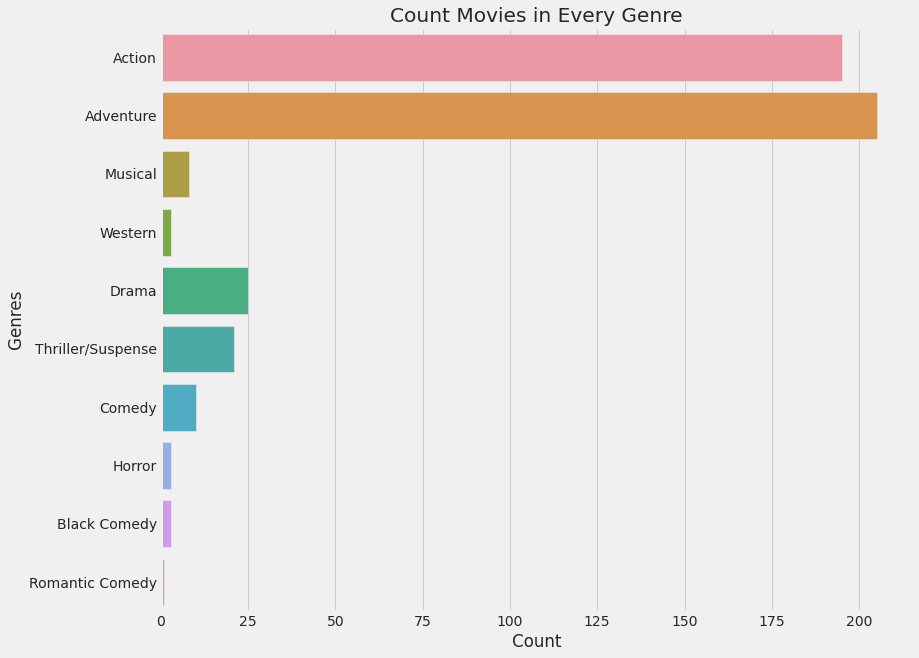

In [ ]:
#Graph show how many movies in every genre
plt.figure(figsize=(12, 10))
plt.title("Count Movies in Every Genre")
Genre_plot = sns.countplot(data = newdf, y = "genre")
Genre_plot.set_xlabel("Count")
Genre_plot.set_ylabel("Genres")
plt.show()

In [ ]:
newdf["year"].value_counts()

2016    34
2013    33
2010    29
2019    27
2017    27
2014    27
2012    26
2015    25
2011    24
2018    23
2009    22
2004    19
2007    18
2021    18
2008    17
2005    14
2003    13
2006    11
2001    11
2002    11
2000     9
2022     8
1997     7
1999     7
2020     5
1998     3
1995     2
1996     2
1991     1
1994     1
Name: year, dtype: int64

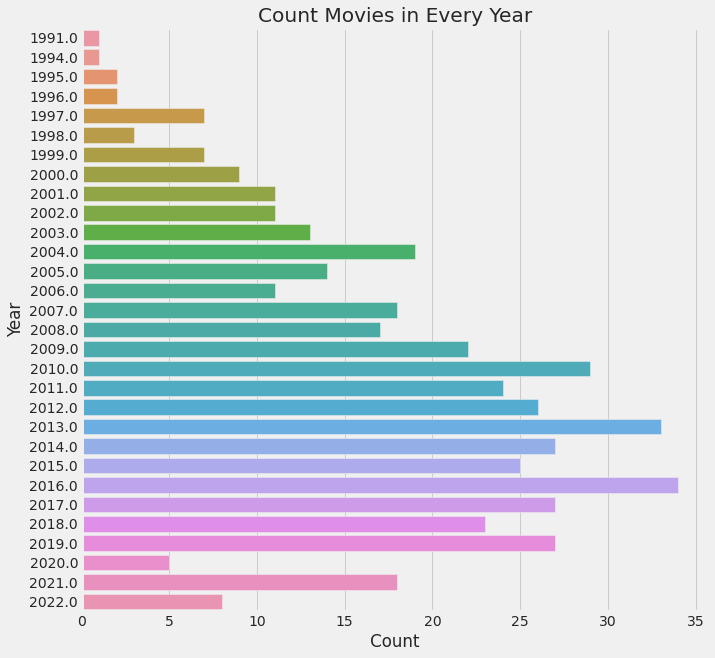

In [ ]:
#Graph show How many movies in every year
plt.figure(figsize=(10, 10))
plt.title("Count Movies in Every Year")
Production_per_year_plot = sns.countplot(data = newdf, y = "year")
Production_per_year_plot.set_xlabel("Count")
Production_per_year_plot.set_ylabel("Year")
plt.show()

In [ ]:
newdf2 = pd.DataFrame(newdf)
sumtotalgross = newdf2['worldwide_gross']
newdf2['totalgross'] = sumtotalgross

profit = newdf2['totalgross'] - newdf2['production_cost']
newdf2['profit'] = profit

#check and remove movies in loss
newdf3 = newdf2[(newdf2[['profit']] >  0).all(axis = 1)] #check and remove ขาดทุน
newdf4 = newdf2[(newdf2[['profit']] <  0).all(axis = 1)]
a = len(newdf3[(newdf3[['profit']] > 0).all(axis = 1)])
b = len(newdf4[(newdf4[['profit']] < 0).all(axis = 1)])
print("There are", a ,"movies that profitable.")
print("and", b ,"movies in loss.")

There are 427 movies that profitable.
and 47 movies in loss.


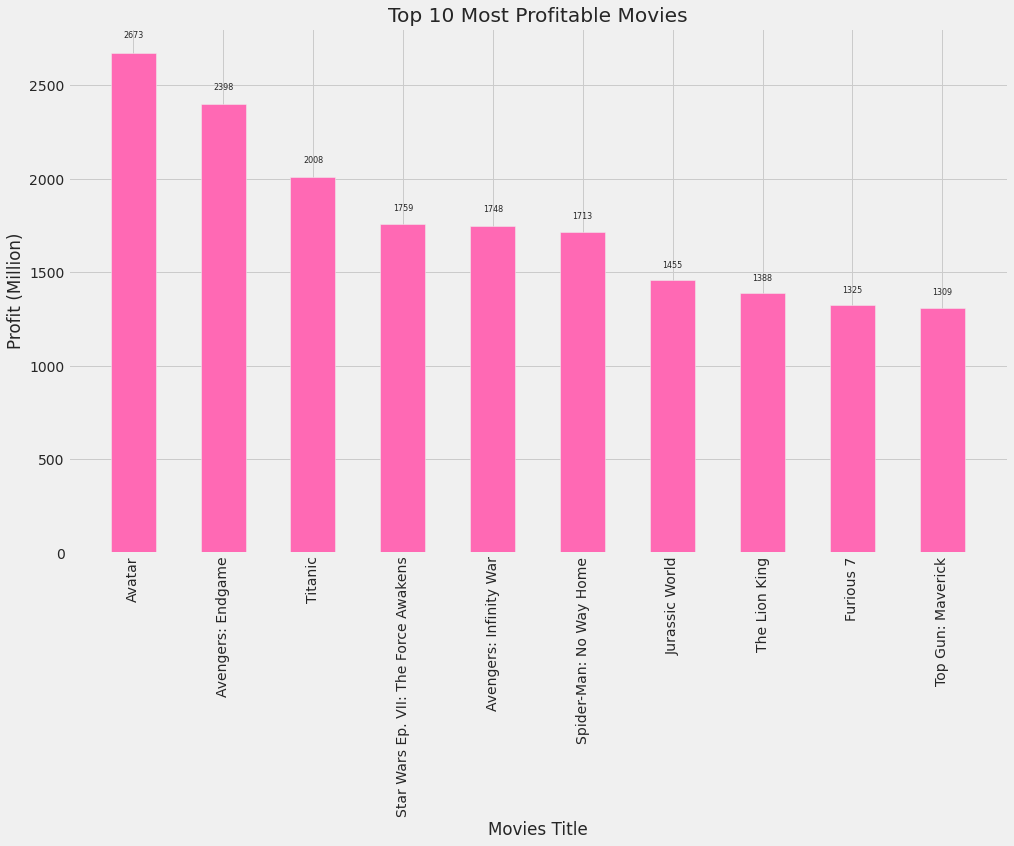

In [ ]:
#sort top10 the most profit and movies title
sort = newdf3['profit'].sort_values(ascending =  False)
top10 = sort.head(10).tolist()

profitsort = newdf3.sort_values(['profit'])
profitsort = newdf3.nlargest(n = 10, columns='profit')
profitsort['title']

#Graph show Top 10 movies that have the most profit
plt.figure(figsize = (15, 9))
plt.title("Top 10 Most Profitable Movies")
top10profit = plt.bar(profitsort['title'], top10, 0.5, color = 'hotpink')
plt.xticks(rotation = 90)
plt.xlabel("Movies Title")
plt.ylabel("Profit (Million)")

i = 0
for p in top10profit:
  width = p.get_width()
  height = p.get_height()
  x, y = p.get_xy()
  plt.text(x + width/2, y + height*1.01, str(round(top10[i]))+'\n', ha = 'center', fontsize = 8)
  i += 1

plt.show()

/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  


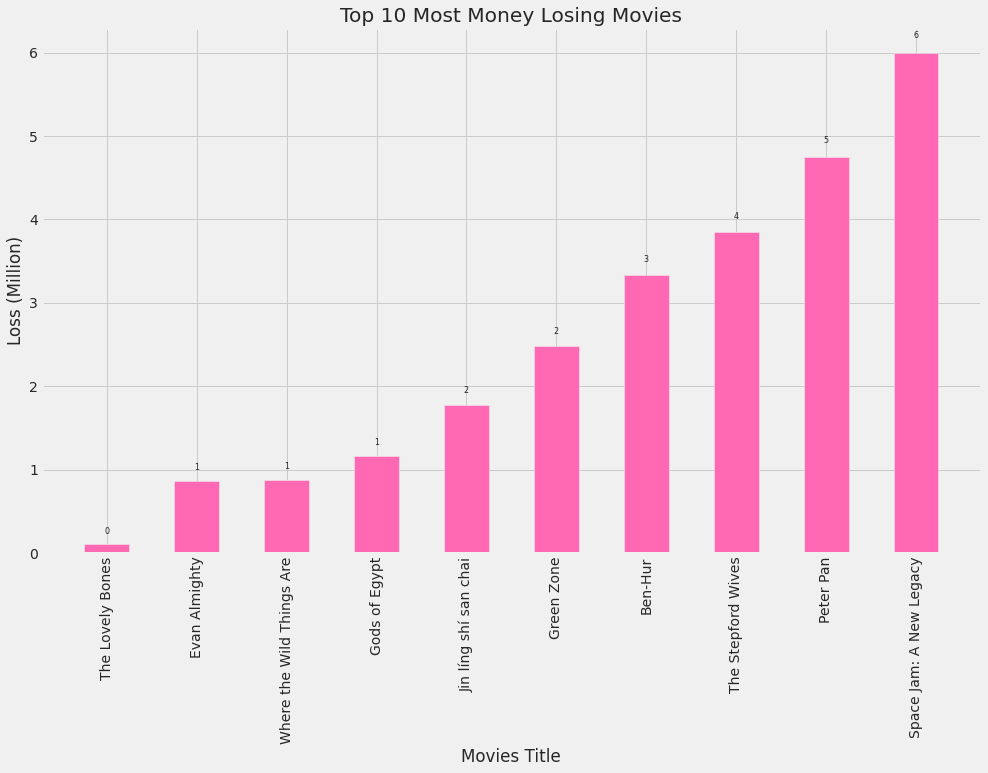

In [ ]:
#sort top10 the most money loss and movies title
newdf4['absprofit'] = newdf4['profit'].abs()
sort2 = newdf4['absprofit'].sort_values()
top10loss = sort2.head(10).tolist()


losssort = newdf4.sort_values(['absprofit'])
losssort = newdf4.nlargest(n = 10, columns='profit')
losssort['title']

#Graph show Top 10 movies that have the most profit
plt.figure(figsize = (15, 9))
plt.title("Top 10 Most Money Losing Movies")
top10lossplt = plt.bar(losssort['title'], top10loss, 0.5, color = 'hotpink')
plt.xticks(rotation = 90)
plt.xlabel("Movies Title")
plt.ylabel("Loss (Million)")

i2 = 0
for p in top10lossplt:
  width = p.get_width()
  height = p.get_height()
  x, y = p.get_xy()
  plt.text(x + width/2, y + height*1.01, str(round(top10loss[i2])) +'\n', ha = 'center', fontsize = 8)
  i2 += 1
plt.show()

In [ ]:
top_10_worldwide_gross = newdf.nlargest(n =10,columns='worldwide_gross')[['title','worldwide_gross','year']].reset_index(drop = True)
top_10_worldwide_gross

,title,worldwide_gross,year
0,Avatar,2910,2009
1,Avengers: Endgame,2798,2019
2,Titanic,2208,1997
3,Star Wars Ep. VII: The Force Awakens,2065,2015
4,Avengers: Infinity War,2048,2018
5,Spider-Man: No Way Home,1913,2021
6,Jurassic World,1670,2015
7,The Lion King,1648,2019
8,The Avengers,1515,2012
9,Furious 7,1515,2015


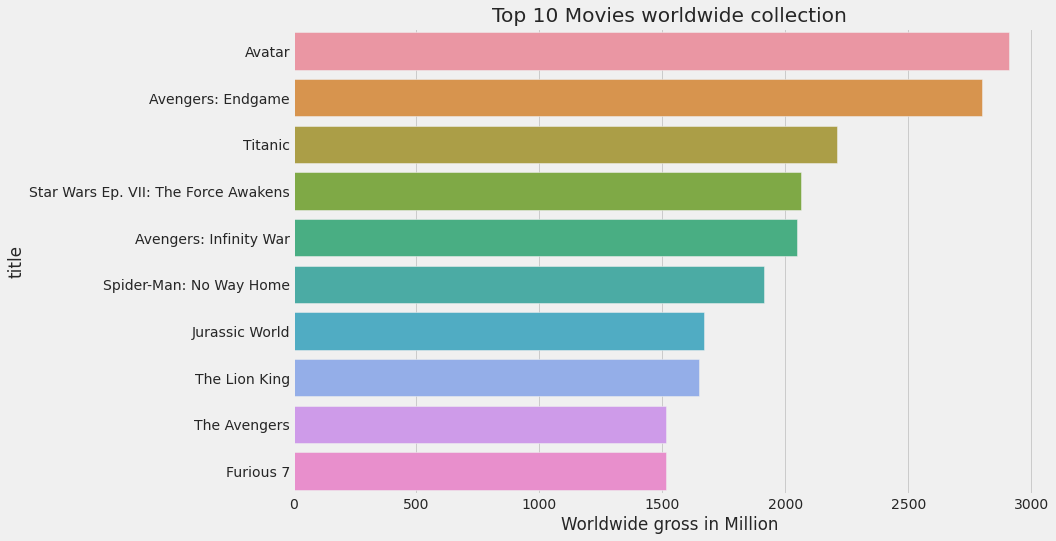

In [ ]:
plt.figure(figsize = (12,8))
sns.barplot(y ='title',x = 'worldwide_gross',orient  = 'h',data=top_10_worldwide_gross)
plt.title('Top 10 Movies worldwide collection')
plt.xlabel("Worldwide gross in Million")
plt.show()

In [ ]:
top_10_production_cost = newdf.nlargest(n =10,columns='production_cost')[['title','production_cost','year']].reset_index(drop = True)
top_10_production_cost

,title,production_cost,year
0,Avengers: Endgame,400,2019
1,Pirates of the Caribbean: On Stranger Tides,379,2011
2,Avengers: Age of Ultron,365,2015
3,Star Wars Ep. VII: The Force Awakens,306,2015
4,Avengers: Infinity War,300,2018
5,Pirates of the Caribbean: At World’s End,300,2007
6,Justice League,300,2017
7,Spectre,300,2015
8,Star Wars: The Rise of Skywalker,275,2019
9,Solo: A Star Wars Story,275,2018


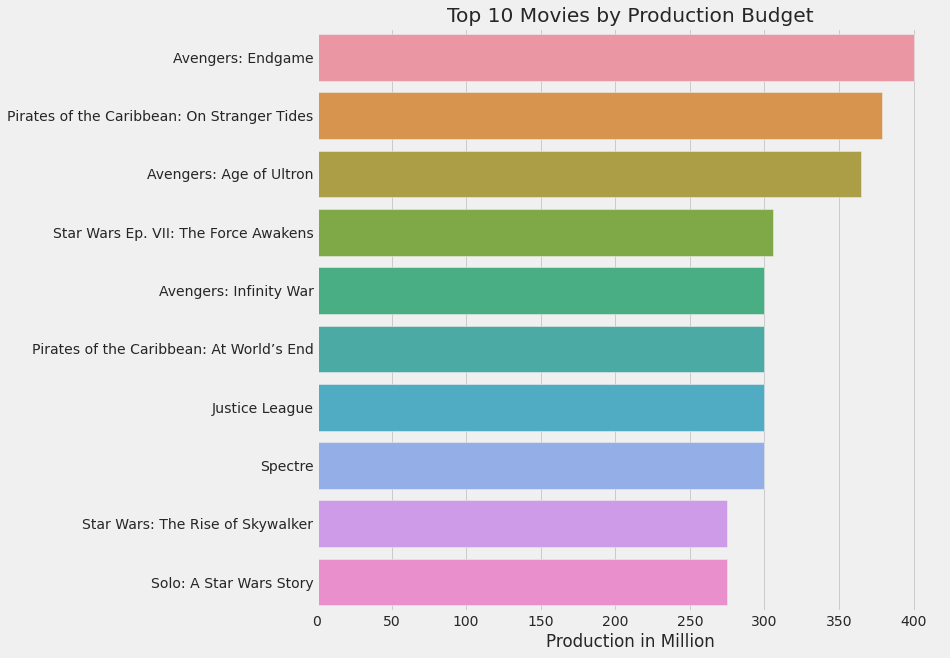

In [ ]:
plt.figure(figsize=(10,10))
plt.title("Top 10 Movies by Production Budget")
top_10_plot = sns.barplot(data=top_10_production_cost , y= "title", x="production_cost")
top_10_plot.set_xlabel("Production in Million")
top_10_plot.set_ylabel("")
plt.show()

In [ ]:
top_10_opening_weekend = newdf.nlargest(n =10,columns='opening_weekend')[['title','opening_weekend','year']].reset_index(drop = True)
top_10_opening_weekend

,title,opening_weekend,year
0,Avengers: Endgame,357,2019
1,Spider-Man: No Way Home,260,2021
2,Avengers: Infinity War,258,2018
3,Star Wars Ep. VII: The Force Awakens,248,2015
4,Star Wars Ep. VIII: The Last Jedi,220,2017
5,Jurassic World,209,2015
6,The Avengers,207,2012
7,Black Panther,202,2018
8,The Lion King,192,2019
9,Avengers: Age of Ultron,191,2015


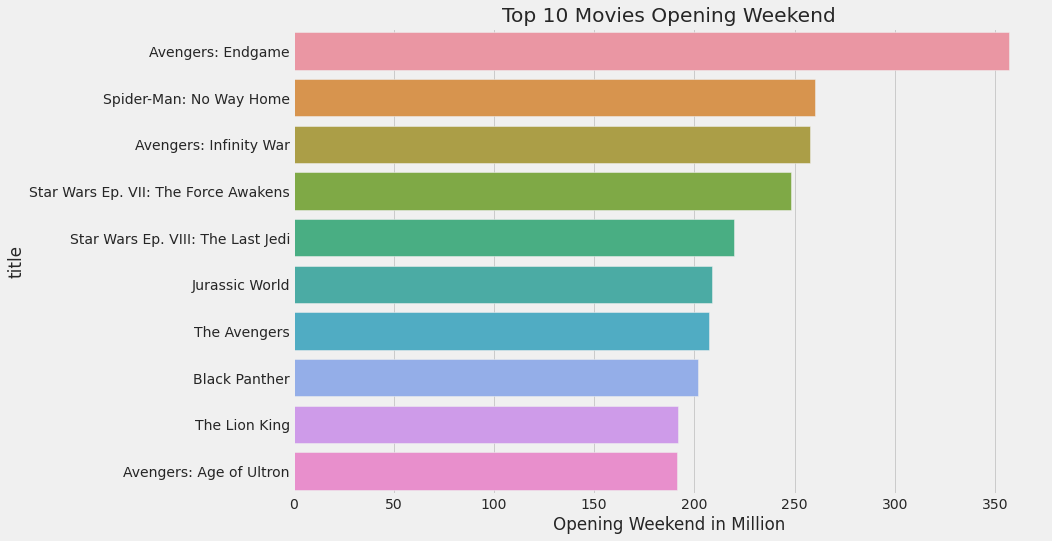

In [ ]:
plt.figure(figsize = (12,8))
sns.barplot(y ='title',x = 'opening_weekend',orient  = 'h',data=top_10_opening_weekend)
plt.title('Top 10 Movies Opening Weekend')
plt.xlabel("Opening Weekend in Million")
plt.show()